# Results: from the classic baseline to the champion

Every policy from the classic baseline to the run1 champion, on the same footing:

- **Past years**: the three expanding folds of the fitness (fit on years before Y, offer on Y = 2007, 2008, 2009).
- **2010**: fit on all of 2006–2009, offer on the 341 listings, scored on the released 2010 prices.

The market rule, folds and value models come from `work/optimization/fitness.py`, so the numbers match the
fitness, `make_offers.py` and `score_2010.py`.

**Read-only analysis after the reveal.** Nothing here changes the champion or the offers. The 2010 numbers
explain the result; they are not used to tune anything.

Run from the repo root (`telco_churn/`). It takes about a minute: each value model is fitted once per fold.

In [1]:
import importlib.util, json, os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Run from the repo root, also when Jupyter starts inside work/analysis/
ROOT = Path.cwd()
while not (ROOT / "earth").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)

spec = importlib.util.spec_from_file_location("fit", "work/optimization/fitness.py")
fit = importlib.util.module_from_spec(spec); spec.loader.exec_module(fit)

F = fit.FitnessClass("work/exploration")
listings = pd.read_csv("data/ames_2010_listings.csv", keep_default_na=False, na_values=[""])
prices = pd.read_csv("data/ames_2010_prices.csv")
y2010 = listings[["ListingID"]].merge(prices, on="ListingID", how="left")["SalePrice"].to_numpy(float)

classic = json.load(open("work/baseline/classic_metrics.json"))
champ = json.load(open("work/runs/run1/champion_chromosome.json"))
history = pd.read_csv("work/runs/run1/history.csv")

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print(f"{len(F.data)} past sales, {len(listings)} listings in 2010, {len(history)} candidates in run1")

2589 past sales, 341 listings in 2010, 5400 candidates in run1


## 1. The stages

Two value models × two kinds of policy, plus one step in between:

| Stage | Value model | Policy |
|---|---|---|
| **A. Classic** | Classic: XGBoost only, best RMSE | Flat 18% (best flat margin on the past years) |
| **B. Classic value + champion policy** | Classic | Champion policy (abstain, segments) |
| **C. Champion value + flat margin** | Champion: 40% quantile XGBoost + 60% ridge | Best flat margin for this model, tuned on the past years |
| **D. Champion value + base + abstain** | Champion | 13.9% base, no offer above 15.6% disagreement, no segments |
| **E. Champion (run1)** | Champion | Full champion policy |

B and C separate the two halves of the champion: is the gain in the **value model** or in the **policy**?

In [2]:
cg = dict(classic["value_genes"])
hg = {k: v for k, v in champ["chromosome"].items() if k != "policy"}
hp = dict(champ["chromosome"]["policy"])

def flat(margin):
    # Offer on every home; only the company's $500k cap on the *offer* applies (as in classic_baseline.py).
    return {"base_margin": margin, "k_disagree": 0.0, "abstain_disagree": 1e12, "max_offer_value": 1e12,
            "adj_high_tier": 0.0, "adj_qual_extreme": 0.0, "adj_age_old": 0.0}

def predictions(genes):
    # One fit per past fold and one on all of 2006-09 for the 2010 listings.
    folds = []
    for (tr, va), year in zip(F.folds, fit.VALID_YEARS):
        v, r, x = fit.Valuer(genes, F.data.columns).fit(F.data.iloc[tr], F.y[tr]).predict(F.data.iloc[va])
        folds.append({"year": year, "x": F.data.iloc[va], "true": F.y[va], "value": v, "ridge": r, "xgb": x})
    v, r, x = fit.Valuer(genes, F.data.columns).fit(F.data, F.y).predict(listings)
    test = {"year": 2010, "x": listings, "true": y2010, "value": v, "ridge": r, "xgb": x}
    return folds, test

pred = {"classic": predictions(cg), "champion": predictions(hg)}
print("value models fitted")

value models fitted


In [3]:
def outcome(p, policy):
    # Per-home results of one policy on one set of predictions (same rule as earth/ibuyer_market.py).
    offer, make = fit.offer_prices(policy, p["value"], p["ridge"], p["xgb"], p["x"])
    make = make & (offer <= fit.MAX_OFFER)
    true = p["true"]
    acc = np.clip((fit.FLEX[1] - (1 - offer / true)) / (fit.FLEX[1] - fit.FLEX[0]), 0, 1) * make
    gain = true * (1 - fit.COST) - offer
    disagree = np.abs(p["xgb"] - p["ridge"]) / p["value"]
    return pd.DataFrame({
        "year": p["year"], "true": true, "value": p["value"], "offer": offer, "make": make,
        "margin": np.where(make, 1 - offer / p["value"], np.nan), "offer_to_true": np.where(make, offer / true, np.nan),
        "p_accept": acc, "profit": acc * gain, "loss": acc * np.minimum(gain, 0),
        "qual": p["x"]["Overall Qual"].to_numpy(), "built": p["x"]["Year Built"].to_numpy(), "disagree": disagree})

def summary(df):
    n = len(df)
    err = (df.value - df.true) / df.true
    return pd.Series({
        "risk_adj": (df.profit.sum() + fit.RISK_WEIGHT * df.loss.sum()) / n,
        "profit": df.profit.sum() / n, "losses": df.loss.sum() / n,
        "share_bought": df.p_accept.sum() / n, "offers_made": df.make.mean(),
        "mean_margin": df.margin.mean(), "MAPE": err.abs().mean(),
        "RMSE": np.sqrt(((df.value - df.true) ** 2).mean()), "overvalued_10pct": (err > 0.10).mean()})

def run(model, policy):
    folds, test = pred[model]
    past = pd.concat([outcome(p, policy) for p in folds], ignore_index=True)
    return past, outcome(test, policy)

# Stage C: the best flat margin for the champion's value model, chosen on the past years only.
grid = np.round(np.arange(0.0, 0.301, 0.01), 2)
flat_scores = pd.Series({m: summary(run("champion", flat(m))[0]).risk_adj for m in grid})
best_flat_champ = float(flat_scores.idxmax())
print(f"best flat margin for the champion value model: {best_flat_champ:.0%} "
      f"({flat_scores.max():+,.0f} $/listing on the past years)")

stages = {
    "A. Classic": ("classic", flat(classic["best_flat"]["margin"])),
    "B. Classic value + champion policy": ("classic", hp),
    f"C. Champion value + flat {best_flat_champ:.0%}": ("champion", flat(best_flat_champ)),
    "D. Champion value + base + abstain": ("champion", {**hp, "k_disagree": 0.0, "adj_high_tier": 0.0,
                                                        "adj_qual_extreme": 0.0, "adj_age_old": 0.0}),
    "E. Champion (run1)": ("champion", hp),
}
results = {name: run(*spec) for name, spec in stages.items()}

best flat margin for the champion value model: 15% (+863 $/listing on the past years)


## 2. All stages: past years and 2010

In [4]:
rows = []
for name, (past, test) in results.items():
    s_past, s_test = summary(past), summary(test)
    rows.append({"stage": name, **{f"past {k}": v for k, v in s_past.items()},
                 **{f"2010 {k}": v for k, v in s_test.items()}})
table = pd.DataFrame(rows).set_index("stage")
for when in ("past", "2010"):
    table[f"{when} score"] = (table[f"{when} risk_adj"] + 3000) / 6000

money = ["risk_adj", "profit", "losses"]
pct = ["share_bought", "offers_made", "mean_margin", "MAPE", "overvalued_10pct"]
fmt = {f"{w} {k}": "{:+,.0f}" for w in ("past", "2010") for k in money}
fmt.update({f"{w} {k}": "{:.1%}" for w in ("past", "2010") for k in pct})
fmt.update({f"{w} RMSE": "${:,.0f}" for w in ("past", "2010")})
fmt.update({f"{w} score": "{:.3f}" for w in ("past", "2010")})
cols = [f"{w} {k}" for w in ("past", "2010") for k in ["score", *money, "share_bought", "mean_margin", "MAPE", "overvalued_10pct"]]
table[cols].style.format(fmt)

,past score,past risk_adj,past profit,past losses,past share_bought,past mean_margin,past MAPE,past overvalued_10pct,2010 score,2010 risk_adj,2010 profit,2010 losses,2010 share_bought,2010 mean_margin,2010 MAPE,2010 overvalued_10pct
stage,,,,,,,,,,,,,,,,
A. Classic,0.473,-160,+547,"-1,416",23.5%,18.0%,8.7%,15.1%,0.467,-200,+448,"-1,296",22.7%,18.0%,10.1%,14.1%
B. Classic value + champion policy,0.565,+392,"+1,115","-1,446",35.3%,14.5%,8.7%,15.1%,0.482,-108,+762,"-1,740",35.0%,14.6%,10.1%,14.1%
C. Champion value + flat 15%,0.644,+863,"+1,366","-1,007",27.6%,15.0%,8.8%,10.7%,0.518,+105,+709,"-1,207",26.1%,15.0%,10.0%,11.7%
D. Champion value + base + abstain,0.664,+983,"+1,436",-905,28.1%,13.9%,8.8%,10.7%,0.565,+390,+911,"-1,041",27.3%,13.9%,10.0%,11.7%
E. Champion (run1),0.673,"+1,038","+1,458",-839,26.9%,14.5%,8.8%,10.7%,0.588,+526,+993,-936,26.0%,14.7%,10.0%,11.7%


In [5]:
# Sanity checks against the numbers already in the report
checks = {
    "A past risk_adj (classic_metrics.json)": (table.loc["A. Classic", "past risk_adj"], classic["best_flat"]["risk_adj_per_listing"]),
    "A 2010 risk_adj (score_2010.py: -68,038 / 341)": (table.loc["A. Classic", "2010 risk_adj"], -68038 / 341),
    "E past risk_adj (one_flip.py, local)": (table.loc["E. Champion (run1)", "past risk_adj"], 1038.05),
    "E 2010 risk_adj (score_2010.py: 179,199 / 341)": (table.loc["E. Champion (run1)", "2010 risk_adj"], 179199 / 341),
}
for k, (got, want) in checks.items():
    print(f"{'OK ' if abs(got - want) < 3 else 'DIFF'} {k}: {got:+,.0f} vs {want:+,.0f}")

OK  A past risk_adj (classic_metrics.json): -160 vs -160
OK  A 2010 risk_adj (score_2010.py: -68,038 / 341): -200 vs -200
OK  E past risk_adj (one_flip.py, local): +1,038 vs +1,038
OK  E 2010 risk_adj (score_2010.py: 179,199 / 341): +526 vs +526


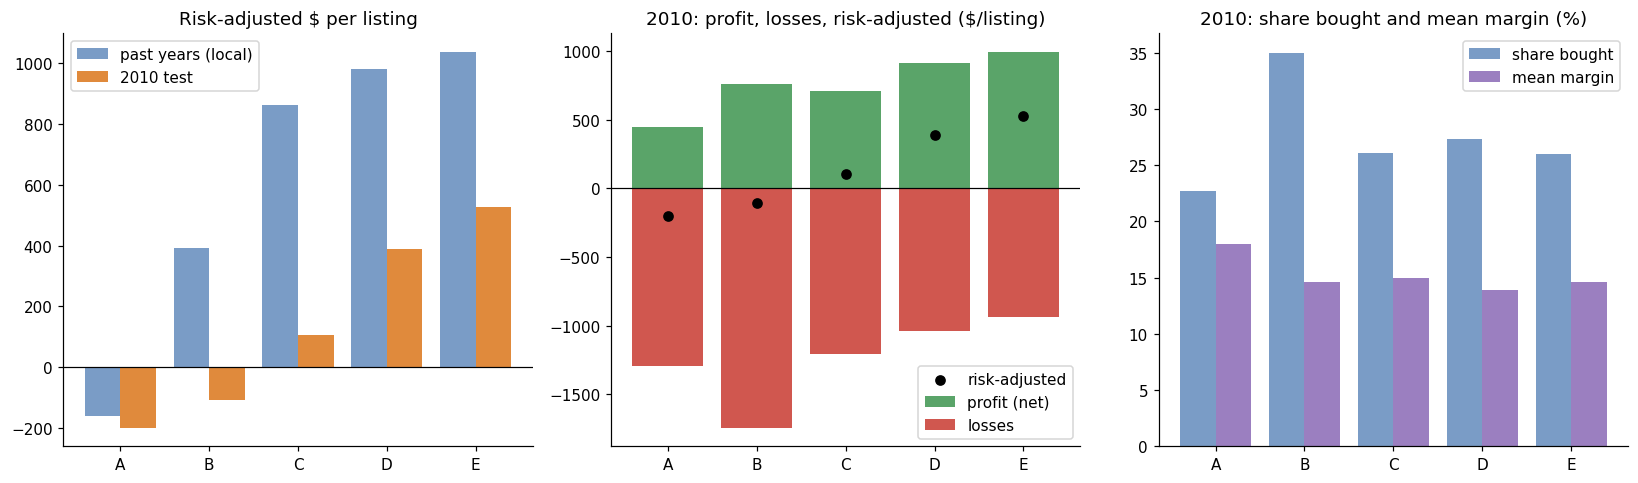

A. Classic
B. Classic value + champion policy
C. Champion value + flat 15%
D. Champion value + base + abstain
E. Champion (run1)


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
names = [n.split(". ")[0] for n in table.index]
xs = np.arange(len(table))

ax = axes[0]
ax.bar(xs - 0.2, table["past risk_adj"], 0.4, label="past years (local)", color="#7a9cc6")
ax.bar(xs + 0.2, table["2010 risk_adj"], 0.4, label="2010 test", color="#e08a3c")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(xs, names); ax.set_title("Risk-adjusted $ per listing"); ax.legend()

ax = axes[1]
ax.bar(xs, table["2010 profit"], color="#5aa469", label="profit (net)")
ax.bar(xs, table["2010 losses"], color="#d0574f", label="losses")
ax.scatter(xs, table["2010 risk_adj"], color="black", zorder=3, label="risk-adjusted")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(xs, names); ax.set_title("2010: profit, losses, risk-adjusted ($/listing)"); ax.legend()

ax = axes[2]
ax.bar(xs - 0.2, table["2010 share_bought"] * 100, 0.4, label="share bought", color="#7a9cc6")
ax.bar(xs + 0.2, table["2010 mean_margin"] * 100, 0.4, label="mean margin", color="#9b7fc0")
ax.set_xticks(xs, names); ax.set_title("2010: share bought and mean margin (%)"); ax.legend()
plt.tight_layout(); plt.show()
print("\n".join(table.index))

**Reading it:** compare A → B (same value model, the policy changes) with A → C (same flat policy, the value
model changes). Whichever step earns more is where the champion's gain comes from. D → E is what the segment
adjustments add.

## 3. Each past year, and 2010

,2007,2008,2009,2010
A. Classic,-593,-25,+173,-200
B. Classic value + champion policy,+937,+609,-399,-108
C. Champion value + flat 15%,+713,"+1,063",+831,+105
D. Champion value + base + abstain,"+1,190","+1,017",+730,+390
E. Champion (run1),"+1,250","+1,041",+808,+526


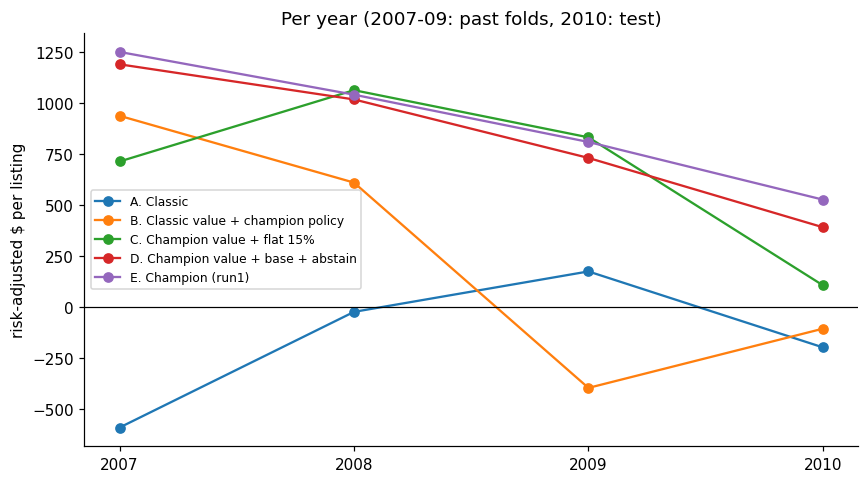

In [7]:
per_year = {}
for name, (past, test) in results.items():
    by = {y: summary(g).risk_adj for y, g in past.groupby("year")}
    by[2010] = summary(test).risk_adj
    per_year[name] = by
per_year = pd.DataFrame(per_year).T
display(per_year.style.format("{:+,.0f}"))

ax = per_year.T.plot(marker="o", figsize=(8, 4.5))
ax.axhline(0, color="black", lw=0.8); ax.set_xticks([2007, 2008, 2009, 2010])
ax.set_ylabel("risk-adjusted $ per listing"); ax.set_title("Per year (2007-09: past folds, 2010: test)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 4. Margins

The margin each policy actually applied: `1 − offer / predicted value`, on the homes that got an offer.

A. Classic - 2010 offers


,listings,mean_margin,min_margin,max_margin
segment,,,,
built before 1920,23,18.0%,18.0%,18.0%
ordinary,268,18.0%,18.0%,18.0%
predicted > $300k,9,18.0%,18.0%,18.0%
quality <= 4 or >= 9,41,18.0%,18.0%,18.0%


E. Champion (run1) - 2010 offers


,listings,mean_margin,min_margin,max_margin
segment,,,,
built before 1920,22,20.8%,19.9%,22.2%
no offer,27,-,-,-
ordinary,254,14.0%,13.9%,14.0%
predicted > $300k,4,12.8%,12.8%,12.8%
quality <= 4 or >= 9,34,16.2%,15.2%,16.3%


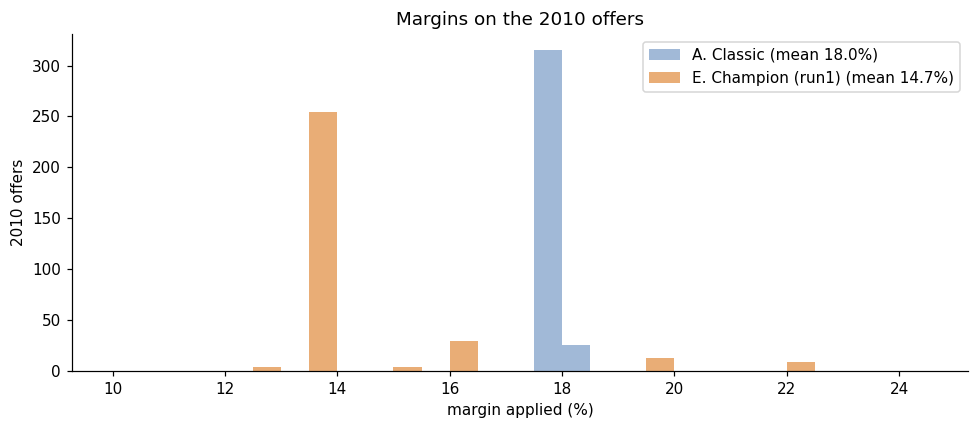

In [8]:
def segment(df):
    seg = np.full(len(df), "ordinary", dtype=object)
    seg[(df.value > 300_000).to_numpy()] = "predicted > $300k"
    seg[((df.qual <= 4) | (df.qual >= 9)).to_numpy()] = "quality <= 4 or >= 9"
    seg[(df.built < 1920).to_numpy()] = "built before 1920"
    seg[~df.make.to_numpy()] = "no offer"
    return seg

for name in ("A. Classic", "E. Champion (run1)"):
    test = results[name][1].assign(segment=lambda d: segment(d))
    t = test.groupby("segment").agg(listings=("make", "size"), mean_margin=("margin", "mean"),
                                    min_margin=("margin", "min"), max_margin=("margin", "max"))
    print(name, "- 2010 offers")
    display(t.style.format({c: "{:.1%}" for c in ["mean_margin", "min_margin", "max_margin"]}, na_rep="-"))

fig, ax = plt.subplots(figsize=(9, 4))
for name, color in (("A. Classic", "#7a9cc6"), ("E. Champion (run1)", "#e08a3c")):
    m = results[name][1].margin.dropna() * 100
    ax.hist(m, bins=np.arange(10, 25, 0.5), alpha=0.7, label=f"{name} (mean {m.mean():.1f}%)", color=color)
ax.set_xlabel("margin applied (%)"); ax.set_ylabel("2010 offers"); ax.set_title("Margins on the 2010 offers"); ax.legend()
plt.tight_layout(); plt.show()

## 5. Where the offers land against the true price

The market rule in one picture: below **80%** of the true price nobody sells; between 80% and **95%** the deal
makes money; above 95% sellers accept and we lose. A good policy puts its offers inside the band and few
above it.

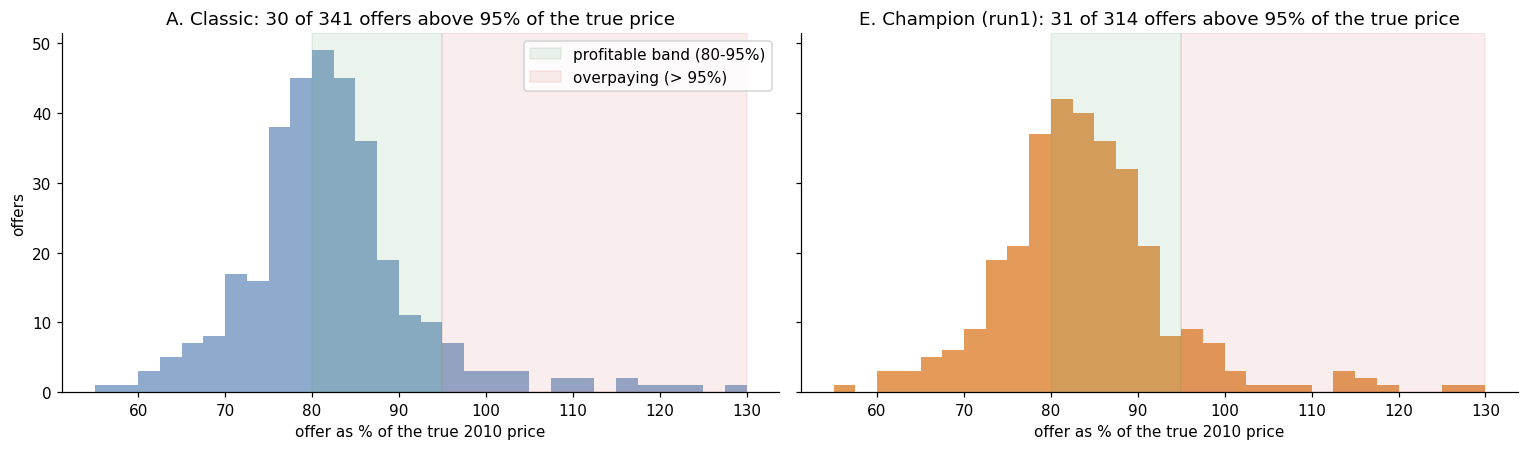

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for ax, name, color in zip(axes, ("A. Classic", "E. Champion (run1)"), ("#7a9cc6", "#e08a3c")):
    test = results[name][1]
    r = test.offer_to_true.dropna() * 100
    ax.hist(r, bins=np.arange(55, 131, 2.5), color=color, alpha=0.85)
    ax.axvspan(80, 95, color="#5aa469", alpha=0.12, label="profitable band (80-95%)")
    ax.axvspan(95, 130, color="#d0574f", alpha=0.10, label="overpaying (> 95%)")
    above = (test.offer_to_true > 0.95).sum()
    ax.set_title(f"{name}: {above} of {int(test.make.sum())} offers above 95% of the true price")
    ax.set_xlabel("offer as % of the true 2010 price")
axes[0].set_ylabel("offers"); axes[0].legend(); plt.tight_layout(); plt.show()

## 6. Value accuracy: similar on average, different in the tail

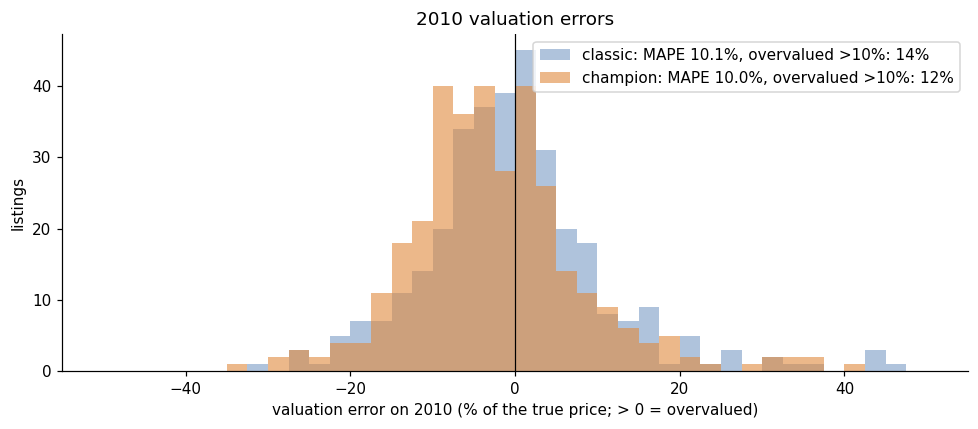

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
for model, color in (("classic", "#7a9cc6"), ("champion", "#e08a3c")):
    test = pred[model][1]
    err = (test["value"] - test["true"]) / test["true"] * 100
    ax.hist(err, bins=np.arange(-50, 51, 2.5), alpha=0.6, color=color,
            label=f"{model}: MAPE {np.abs(err).mean():.1f}%, overvalued >10%: {(err > 10).mean():.0%}")
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("valuation error on 2010 (% of the true price; > 0 = overvalued)"); ax.set_ylabel("listings")
ax.set_title("2010 valuation errors"); ax.legend(); plt.tight_layout(); plt.show()

## 7. Which homes earned the difference (classic vs champion)

In [11]:
for when, i in (("past years", 0), ("2010", 1)):
    a, e = results["A. Classic"][i], results["E. Champion (run1)"][i]
    # Same homes in both tables, grouped by the home (from the champion's view), not by the decision.
    skip = (e.disagree > hp["abstain_disagree"]).to_numpy()
    groups = np.where(skip, "models disagree (champion skips)", segment(e.assign(make=True)))
    sa = a.assign(segment=groups, r=a.profit + fit.RISK_WEIGHT * a.loss).groupby("segment")
    se = e.assign(segment=groups, r=e.profit + fit.RISK_WEIGHT * e.loss).groupby("segment")
    out = pd.DataFrame({
        "homes": sa.size(),
        "classic bought": sa.p_accept.sum(), "champion bought": se.p_accept.sum(),
        "classic $/listing": sa.r.sum() / len(a), "champion $/listing": se.r.sum() / len(e)})
    out["gain"] = out["champion $/listing"] - out["classic $/listing"]
    print(f"{when}: gain by group of homes (sums to the total gain per listing: {out.gain.sum():+,.0f})")
    display(out.style.format({"classic bought": "{:.1f}", "champion bought": "{:.1f}",
                              "classic $/listing": "{:+,.0f}", "champion $/listing": "{:+,.0f}", "gain": "{:+,.0f}"}))

past years: gain by group of homes (sums to the total gain per listing: +1,199)


,homes,classic bought,champion bought,classic $/listing,champion $/listing,gain
segment,,,,,,
built before 1920,100,35.7,18.8,-108,-26,+82
models disagree (champion skips),199,37.9,0.0,-600,+0,+600
ordinary,1423,317.2,442.7,+748,"+1,146",+399
predicted > $300k,50,13.3,19.8,-22,-18,+5
quality <= 4 or >= 9,192,56.9,46.3,-178,-65,+113


2010: gain by group of homes (sums to the total gain per listing: +725)


,homes,classic bought,champion bought,classic $/listing,champion $/listing,gain
segment,,,,,,
built before 1920,22,8.0,4.4,-209,-85,+125
models disagree (champion skips),27,6.2,0.0,-434,+0,+434
ordinary,254,52.7,74.2,+471,+685,+214
predicted > $300k,4,0.6,0.9,+59,+76,+17
quality <= 4 or >= 9,34,9.9,9.2,-86,-151,-65


## 8. How the search got there (run1 on Earth)

Earth's scores are on the past years, as Earth's workers computed them (about $225 per listing above the local
re-score for the top candidates; see the report).

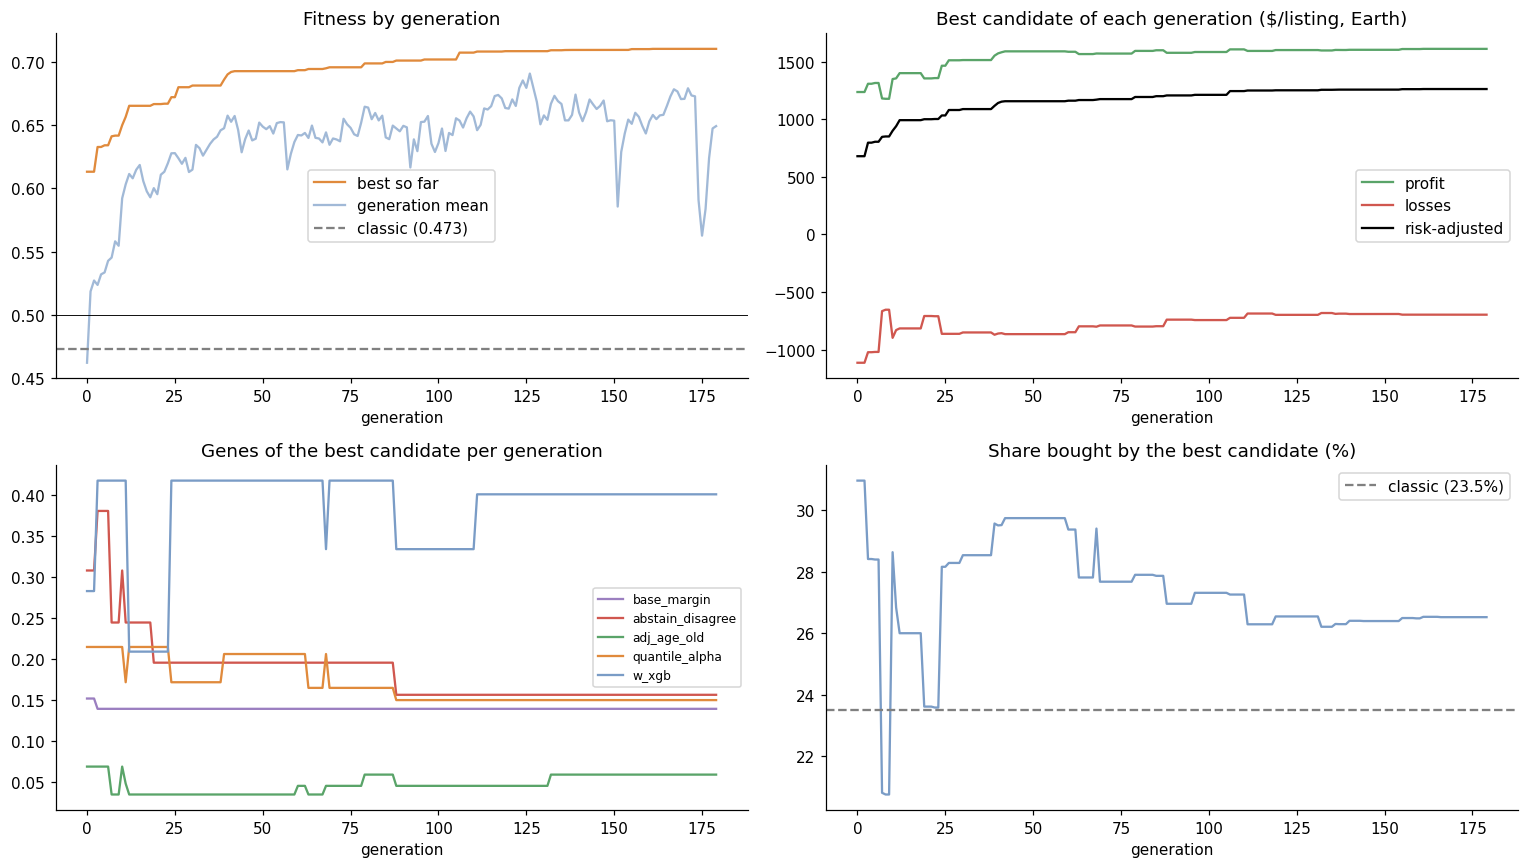

In [12]:
import ast
h = history.copy()
pol = h["gene.policy"].apply(ast.literal_eval).apply(pd.Series)
h = pd.concat([h, pol], axis=1)
best = h.loc[h.groupby("generation").score.idxmax()].set_index("generation")
best["best_so_far"] = best.score.cummax()
mean = h.groupby("generation").score.mean()

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
ax = axes[0, 0]
ax.plot(best.index, best.best_so_far, label="best so far", color="#e08a3c")
ax.plot(mean.index, mean, label="generation mean", color="#7a9cc6", alpha=0.7)
ax.axhline(0.473, color="gray", ls="--", label="classic (0.473)")
ax.axhline(0.5, color="black", lw=0.6)
ax.set_title("Fitness by generation"); ax.set_xlabel("generation"); ax.legend()

ax = axes[0, 1]
ax.plot(best.index, best["scalar.profit_per_listing"], label="profit", color="#5aa469")
ax.plot(best.index, best["scalar.losses_per_listing"], label="losses", color="#d0574f")
ax.plot(best.index, best["scalar.risk_adj_per_listing"], label="risk-adjusted", color="black")
ax.set_title("Best candidate of each generation ($/listing, Earth)"); ax.set_xlabel("generation"); ax.legend()

ax = axes[1, 0]
for gene, color in (("base_margin", "#9b7fc0"), ("abstain_disagree", "#d0574f"), ("adj_age_old", "#5aa469")):
    ax.plot(best.index, best[gene], label=gene, color=color)
ax.plot(best.index, best["gene.quantile_alpha"], label="quantile_alpha", color="#e08a3c")
ax.plot(best.index, best["gene.w_xgb"], label="w_xgb", color="#7a9cc6")
ax.set_title("Genes of the best candidate per generation"); ax.set_xlabel("generation"); ax.legend(fontsize=8)

ax = axes[1, 1]
ax.plot(best.index, best["scalar.share_bought"] * 100, color="#7a9cc6")
ax.axhline(23.5, color="gray", ls="--", label="classic (23.5%)")
ax.set_title("Share bought by the best candidate (%)"); ax.set_xlabel("generation"); ax.legend()
plt.tight_layout(); plt.show()

## 9. From Earth's 0.710 to the 2010 result

,Champion,Classic,Champion score
"Earth, 3 past years","+1,263",-,0.710
"Local, 3 past years","+1,038",-160,0.673
"Local, 2009 only",+808,+173,0.635
2010 test,+526,-200,0.588


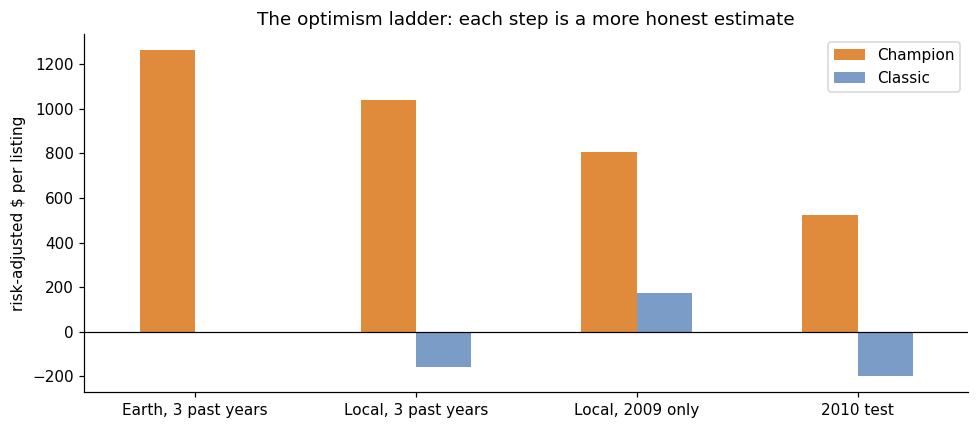

In [13]:
e_past, e_test = results["E. Champion (run1)"]
a_past, a_test = results["A. Classic"]
ladder = pd.DataFrame({
    "Champion": [champ["fitness_score"] * 6000 - 3000, summary(e_past).risk_adj,
                 summary(e_past[e_past.year == 2009]).risk_adj, summary(e_test).risk_adj],
    "Classic": [np.nan, summary(a_past).risk_adj, summary(a_past[a_past.year == 2009]).risk_adj, summary(a_test).risk_adj],
}, index=["Earth, 3 past years", "Local, 3 past years", "Local, 2009 only", "2010 test"])
ladder["Champion score"] = (ladder.Champion + 3000) / 6000
display(ladder.style.format({"Champion": "{:+,.0f}", "Classic": "{:+,.0f}", "Champion score": "{:.3f}"}, na_rep="-"))

ax = ladder[["Champion", "Classic"]].plot.bar(figsize=(9, 4), color=["#e08a3c", "#7a9cc6"], rot=0)
ax.axhline(0, color="black", lw=0.8); ax.set_ylabel("risk-adjusted $ per listing")
ax.set_title("The optimism ladder: each step is a more honest estimate"); plt.tight_layout(); plt.show()